In [1]:
import pandas as pd
import numpy as np
import keras
from keras import models
from keras import layers
from keras.models import Sequential
from keras.layers import Dense
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Dataset loaded successfully!
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


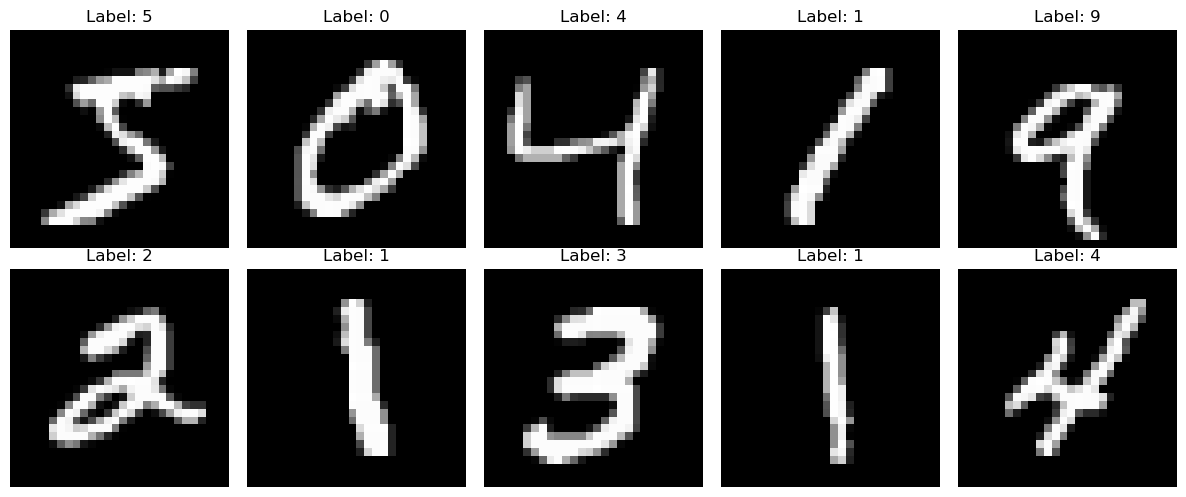

In [2]:
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist

# Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Dataset loaded successfully!")
print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

# Plot first 10 images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title("Label: " + str(y_train[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()


In [3]:
X_val = X_train[54000:]
y_val = y_train[54000:]

X_train = X_train[:54000]
y_train = y_train[:54000]

print("\nAfter splitting:")
print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))


After splitting:
Training samples: 54000
Validation samples: 6000
Testing samples: 10000


In [5]:
x_train = X_train.astype("float32") / 255.0
x_val = X_val.astype("float32") / 255.0
x_test = X_test.astype("float32") / 255.0

x_train = np.expand_dims(x_train, axis=-1)
x_val = np.expand_dims(x_val, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print("\nProcessed data shapes:")
print("x_train:", x_train.shape)
print("x_val:  ", x_val.shape)
print("x_test: ", x_test.shape)

print("\nPixel value range:")
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())



Processed data shapes:
x_train: (54000, 28, 28, 1)
x_val:   (6000, 28, 28, 1)
x_test:  (10000, 28, 28, 1)

Pixel value range:
Minimum: 0.0
Maximum: 1.0


In [ ]:

input_img = keras.Input(shape=(28, 28, 1), name="input_image")

x = layers.Conv2D(
    32, kernel_size=(3, 3),
    activation="relu", padding="same"
)(input_img)

x = layers.MaxPooling2D(
    pool_size=(2, 2), padding="same"
)(x)

x = layers.Conv2D(
    64, kernel_size=(3, 3),
    activation="relu", padding="same"
)(x)

encoded = layers.MaxPooling2D(
    pool_size=(2, 2), padding="same",
    name="encoded_representation"
)(x)

x = layers.Conv2D(
    64, kernel_size=(3, 3),
    activation="relu", padding="same"
)(encoded)

x = layers.UpSampling2D(size=(2, 2))(x)

x = layers.Conv2D(
    32, kernel_size=(3, 3),
    activation="relu", padding="same"
)(x)

x = layers.UpSampling2D(size=(2, 2))(x)

decoded = layers.Conv2D(
    1, kernel_size=(3, 3),
    activation="sigmoid", padding="same",
    name="reconstructed_image"
)(x)

autoencoder = keras.Model(
    inputs=input_img,
    outputs=decoded,
    name="MNIST_Convolutional_Autoencoder"
)

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.summary()


Model: "MNIST_Convolutional_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoded_representation          │ (None, 7, 7, 64)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_image (Conv2D)    │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = autoencoder.fit(
    x_train, x_train,
    epochs=10,
    batch_size=128,
    shuffle=True,
    validation_data=(x_val, x_val)
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 123ms/step - loss: 0.1065 - val_loss: 0.0759
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 135ms/step - loss: 0.0729 - val_loss: 0.0717
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 63s 150ms/step - loss: 0.0702 - val_loss: 0.0700
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 57s 134ms/step - loss: 0.0688 - val_loss: 0.0688
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 61s 145ms/step - loss: 0.0679 - val_loss: 0.0680
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 60s 142ms/step - loss: 0.0672 - val_loss: 0.0673
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 68s 109ms/step - loss: 0.0666 - val_loss: 0.0671
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 61s 143ms/step - loss: 0.0661 - val_loss: 0.0667
Epoch 9/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 64s 152ms/step - loss: 0.0657 - val_loss: 0.0662
Epoch 10/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 64s 151ms/step - loss: 0.0654 - val_loss: 0.0657


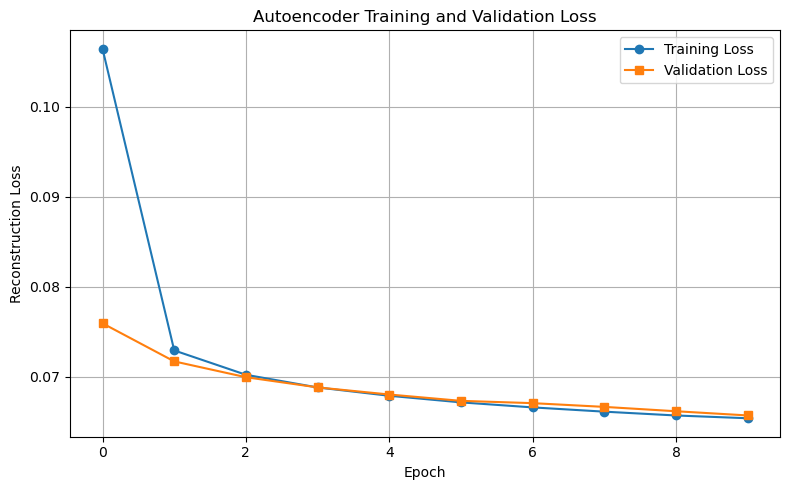

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss',
    marker='o'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss',
    marker='s'
)

plt.title('Autoencoder Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
